# 04. Segunda etapa de modelagem — Random Forest

Este notebook implementa uma segunda etapa deliberadamente simples, mantendo a mesma lógica de avaliação do baseline.

## Objetivos
- **Regressão:** comparar Ridge com `RandomForestRegressor`.
- **Classificação:** comparar Regressão Logística com `RandomForestClassifier`.

## Por que Random Forest nesta etapa?
É um próximo passo natural após modelos lineares porque:
- captura relações não lineares;
- captura interações entre prazo, execução e financeiro;
- exige pouca preparação;
- é relativamente robusto;
- permite interpretação por importância das variáveis.

## Regras preservadas
- split temporal por contrato;
- pesos por contrato;
- exclusão de leakage;
- classificação apenas antes do vencimento do prazo;
- threshold escolhido somente na validação;
- teste reservado para avaliação final;
- análise complementar por contrato em horizonte aproximadamente fixo.


## Atualização — conclusão definitiva

Este notebook foi adaptado para o dataset em que:

`data_conclusao_definitiva = data_recebimento_provisorio`

Os targets (`target_dias_atraso` e `target_atraso`) já chegam calculados pelo notebook 01.
A `data_conclusao_definitiva` é usada apenas para split temporal, auditoria e validações,
e nunca entra como feature do modelo.


In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 1. Carregamento e compatibilidade com V1/V2

In [4]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
METRICS_DIR = ARTIFACTS_DIR / "metrics"
PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"

for folder in [METRICS_DIR, PREDICTIONS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# IMPORTANTE: prioriza a versão baseada em recebimento provisório.
candidate_paths = [
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots_receb_prov.csv",
    PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots_receb_prov.csv",
    PROJECT_ROOT / "dataset_modelagem_obras_snapshots.csv",
    Path("/mnt/data/dataset_modelagem_obras_snapshots_receb_prov.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots.csv"),
]

DATASET_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError(
        "Dataset atualizado não encontrado. Execute primeiro o notebook 01 "
        "baseado na data de recebimento provisório."
    )

df = pd.read_csv(DATASET_PATH, low_memory=False)

for c in [
    "data_corte",
    "data_os",
    "data_termino_original",
    "data_termino_vigente_corte",
    "data_conclusao_definitiva",
    "data_conclusao_controle",
    "data_conclusao_sistema_controle",
    "data_termino_vigente_final_controle",
]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

required_base = [
    "id_contrato",
    "data_corte",
    "target_dias_atraso",
    "target_atraso",
    "flag_apto_treino",
    "dias_restantes_prazo_vigente",
    "data_conclusao_definitiva",
    "data_termino_vigente_final_controle",
]

# missing = [c for c in required_base if c not in df.columns]
# if missing:
#     raise ValueError(
#         "O dataset carregado não parece ser a nova versão baseada em recebimento provisório. "
#         f"Colunas ausentes: {missing}"
#     )

# Alias mantido por compatibilidade.
if "data_conclusao_controle" not in df.columns:
    df["data_conclusao_controle"] = df["data_conclusao_definitiva"]

# Confirma consistência do target de regressão.
mask_target = (
    df["data_conclusao_definitiva"].notna()
    & df["data_termino_vigente_final_controle"].notna()
    & df["target_dias_atraso"].notna()
)

target_recalculado = (
    df.loc[mask_target, "data_conclusao_definitiva"]
    - df.loc[mask_target, "data_termino_vigente_final_controle"]
).dt.days.clip(lower=0)

if not np.allclose(
    target_recalculado.astype(float),
    df.loc[mask_target, "target_dias_atraso"].astype(float),
    equal_nan=True,
):
    raise ValueError(
        "target_dias_atraso não está consistente com a nova data de conclusão definitiva."
    )

# Cria peso por contrato se ainda não existir.
if "sample_weight_contrato" not in df.columns:
    counts = (
        df[df["flag_apto_treino"].eq(1)]
        .groupby("id_contrato")
        .size()
    )
    df["sample_weight_contrato_raw"] = df["id_contrato"].map(
        lambda cid: 1.0 / counts[cid] if cid in counts.index else np.nan
    )
    mean_w = df.loc[
        df["flag_apto_treino"].eq(1),
        "sample_weight_contrato_raw"
    ].mean()
    df["sample_weight_contrato"] = (
        df["sample_weight_contrato_raw"] / mean_w
    )

# Cria split temporal usando a nova conclusão definitiva.
if "split_modelagem" not in df.columns:
    contratos_rotulados = (
        df[df["flag_apto_treino"].eq(1)]
        .groupby("id_contrato")["data_conclusao_definitiva"]
        .max()
        .dropna()
        .sort_values()
    )

    n = len(contratos_rotulados)
    n_train = int(np.floor(n * 0.70))
    n_val = int(np.floor(n * 0.15))

    ids_train = set(contratos_rotulados.index[:n_train])
    ids_val = set(contratos_rotulados.index[n_train:n_train+n_val])
    ids_test = set(contratos_rotulados.index[n_train+n_val:])

    df["split_contrato_temporal"] = "scoring"
    df.loc[df["id_contrato"].isin(ids_train), "split_contrato_temporal"] = "train"
    df.loc[df["id_contrato"].isin(ids_val), "split_contrato_temporal"] = "validation"
    df.loc[df["id_contrato"].isin(ids_test), "split_contrato_temporal"] = "test"

    df["split_modelagem"] = np.where(
        df["flag_apto_treino"].eq(1),
        df["split_contrato_temporal"],
        "nao_supervisionado",
    )

if "split_contrato_temporal" not in df.columns:
    contract_split = (
        df[df["split_modelagem"].isin(["train", "validation", "test"])]
        .drop_duplicates("id_contrato")
        .set_index("id_contrato")["split_modelagem"]
        .to_dict()
    )
    df["split_contrato_temporal"] = (
        df["id_contrato"].map(contract_split).fillna("scoring")
    )

print("Dataset:", DATASET_PATH.resolve())
print("Shape:", df.shape)
print("Contratos:", df["id_contrato"].nunique())
print(
    "Contratos com conclusão definitiva:",
    df.loc[df["data_conclusao_definitiva"].notna(), "id_contrato"].nunique()
)
display(df["split_modelagem"].value_counts().rename("snapshots").to_frame())


Dataset: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots.csv
Shape: (1657, 49)
Contratos: 78
Contratos com conclusão definitiva: 52


,snapshots
split_modelagem,
nao_supervisionado,992
train,400
test,149
validation,116


## 2. Amostras supervisionadas

A regressão usa todos os snapshots rotulados anteriores à conclusão definitiva.

A classificação usa apenas snapshots com `dias_restantes_prazo_vigente >= 0`.
Isso mantém o problema genuinamente preditivo: depois do vencimento, o atraso já teria ocorrido.


In [5]:
valid_splits = ["train", "validation", "test"]

model_data = df[
    df["flag_apto_treino"].eq(1)
    & df["split_modelagem"].isin(valid_splits)
].copy()

reg_data = model_data.copy()

# Para classificação, excluir snapshots em que o prazo já venceu.
clf_data = model_data[
    model_data["dias_restantes_prazo_vigente"].ge(0)
].copy()

summary = pd.DataFrame({
    "amostra": ["regressao", "classificacao_pre_prazo"],
    "snapshots": [len(reg_data), len(clf_data)],
    "contratos": [
        reg_data["id_contrato"].nunique(),
        clf_data["id_contrato"].nunique(),
    ],
    "taxa_atraso": [
        reg_data["target_atraso"].mean(),
        clf_data["target_atraso"].mean(),
    ],
})
display(summary)


,amostra,snapshots,contratos,taxa_atraso
0,regressao,665,52,0.4767
1,classificacao_pre_prazo,574,52,0.4094


## 3. Features

In [6]:
numeric_candidates = [
    "valor_total_contrato",
    "prazo_original_dias",
    "dias_desde_os",
    "dias_restantes_prazo_vigente",
    "pct_prazo_consumido",
    "qtd_aditivos_prazo",
    "dias_aditados_acumulados",
    "pct_dias_aditados_sobre_prazo_original",
    "qtd_aditivos_valor",
    "pct_parcelas_concluidas_vs_previstas",
    "atraso_medio_parcelas_dias",
    "atraso_maximo_parcelas_dias",
    "pct_parcelas_atrasadas",
    "atraso_medio_parcelas_90d",
    "qtd_parcelas_atrasadas_90d",
    "pct_financeiro_liberado",
    "gap_prazo_financeiro",
    "atraso_medio_liberacao_dias",
    "atraso_maximo_liberacao_dias",
    # V2 enriquecida
    "recent_atraso_medio_parcelas_30d",
    "recent_atraso_medio_parcelas_90d",
    "recent_pct_parcelas_atrasadas_90d",
    "delta_atraso_90d_vs_historico",
    "dias_desde_ultima_parcela_concluida",
    "recent_atraso_medio_liberacao_90d",
    "dias_desde_ultima_liberacao",
    "gap_prazo_execucao",
    "pressao_tempo_financeiro",
    "pressao_tempo_execucao",
    "mes_sin",
    "mes_cos",
]

numeric_features = [c for c in numeric_candidates if c in df.columns]

if "classificacao_contrato_agrupada" in df.columns:
    categorical_features = ["classificacao_contrato_agrupada"]
elif "classificacao_contrato" in df.columns:
    categorical_features = ["classificacao_contrato"]
else:
    categorical_features = []

features = numeric_features + categorical_features

print("Features numéricas:", len(numeric_features))
print("Features categóricas:", len(categorical_features))
print("Total:", len(features))


Features numéricas: 18
Features categóricas: 1
Total: 19


## 4. Preprocessamento

In [7]:
tree_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
])

linear_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

tree_preprocessing = ColumnTransformer(
    transformers=[
        ("numeric", tree_numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

linear_preprocessing = ColumnTransformer(
    transformers=[
        ("numeric", linear_numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

def split_xy(data, split):
    part = data[data["split_modelagem"].eq(split)].copy()
    X = part[features]
    y_reg = part["target_dias_atraso"].astype(float)
    y_clf = part["target_atraso"].astype(int)
    w = part["sample_weight_contrato"].astype(float)
    return part, X, y_reg, y_clf, w


# Parte A — Regressão

In [8]:
reg_train, Xr_train, yr_train, _, wr_train = split_xy(reg_data, "train")
reg_val, Xr_val, yr_val, _, wr_val = split_xy(reg_data, "validation")
reg_test, Xr_test, yr_test, _, wr_test = split_xy(reg_data, "test")

regression_models = {
    "dummy_mediana": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", DummyRegressor(strategy="median")),
    ]),
    "ridge": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", Ridge(alpha=10.0)),
    ]),
    "random_forest": Pipeline([
        ("preprocessing", clone(tree_preprocessing)),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=8,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}


In [9]:
def regression_metrics(y_true, y_pred, sample_weight=None):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "mae_ponderado": mean_absolute_error(
            y_true, y_pred, sample_weight=sample_weight
        ),
        "mae_sem_peso": mean_absolute_error(y_true, y_pred),
        "medae_sem_peso": median_absolute_error(y_true, y_pred),
        "rmse_ponderado": mean_squared_error(
            y_true, y_pred, sample_weight=sample_weight
        ) ** 0.5,
        "r2_ponderado": r2_score(
            y_true, y_pred, sample_weight=sample_weight
        ),
        "pct_erro_ate_30d_ponderado": np.average(
            np.abs(y_true - y_pred) <= 30,
            weights=sample_weight,
        ),
        "erro_medio_assinado_ponderado": np.average(
            y_pred - y_true,
            weights=sample_weight,
        ),
    }

regression_results = []
fitted_regression = {}

for name, model in regression_models.items():
    model.fit(Xr_train, yr_train, model__sample_weight=wr_train)
    fitted_regression[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xr_val, yr_val, wr_val),
        ("test", Xr_test, yr_test, wr_test),
    ]:
        pred = np.maximum(0, model.predict(X_))
        row = {"modelo": name, "split": split_name}
        row.update(regression_metrics(y_, pred, w_))
        regression_results.append(row)

regression_metrics_df = pd.DataFrame(regression_results)

display(
    regression_metrics_df
    .sort_values(["split", "mae_ponderado"])
    .reset_index(drop=True)
)


,modelo,split,mae_ponderado,mae_sem_peso,medae_sem_peso,rmse_ponderado,r2_ponderado,pct_erro_ate_30d_ponderado,erro_medio_assinado_ponderado
0,dummy_mediana,test,36.6667,39.6376,23.0000,63.0925,-0.5100,0.6667,-36.6667
1,random_forest,test,40.0092,40.8809,41.7755,47.2480,0.1532,0.3382,8.6663
2,ridge,test,53.0964,53.8236,53.9416,61.5828,-0.4386,0.2446,12.2697
3,dummy_mediana,validation,12.7143,17.2500,0.0000,28.8370,-0.2413,0.8571,-12.7143
4,ridge,validation,21.8810,26.8027,21.4505,30.8980,-0.4251,0.7040,10.7808
5,random_forest,validation,27.2807,32.1643,29.2622,30.4601,-0.3850,0.6833,18.6714


### Seleção na validação e avaliação final

In [10]:
best_reg_name = (
    regression_metrics_df[
        regression_metrics_df["split"].eq("validation")
    ]
    .sort_values("mae_ponderado")
    .iloc[0]["modelo"]
)
best_reg = fitted_regression[best_reg_name]

print("Melhor modelo na validação:", best_reg_name)

reg_test_eval = reg_test.copy()
reg_test_eval["pred_dias_atraso"] = np.maximum(
    0, best_reg.predict(Xr_test)
)
reg_test_eval["erro_abs"] = np.abs(
    reg_test_eval["target_dias_atraso"]
    - reg_test_eval["pred_dias_atraso"]
)

display(
    reg_test_eval[
        [
            "id_contrato", "data_corte", "faixa_antecedencia",
            "target_dias_atraso", "pred_dias_atraso", "erro_abs"
        ]
    ].head(15)
)


Melhor modelo na validação: dummy_mediana


,id_contrato,data_corte,faixa_antecedencia,target_dias_atraso,pred_dias_atraso,erro_abs
1056,217,2023-05-25,>=180d,68.0000,0.0000,68.0000
1057,217,2023-05-31,>=180d,68.0000,0.0000,68.0000
1058,217,2023-06-30,>=180d,68.0000,0.0000,68.0000
1059,217,2023-07-31,>=180d,68.0000,0.0000,68.0000
1060,217,2023-08-31,>=180d,68.0000,0.0000,68.0000
1061,217,2023-09-30,>=180d,68.0000,0.0000,68.0000
1062,217,2023-10-31,>=180d,68.0000,0.0000,68.0000
1063,217,2023-11-30,>=180d,68.0000,0.0000,68.0000
1064,217,2023-12-31,>=180d,68.0000,0.0000,68.0000
1065,217,2024-01-31,>=180d,68.0000,0.0000,68.0000


In [11]:
horizon_reg = (
    reg_test_eval
    .groupby("faixa_antecedencia", observed=True)
    .apply(
        lambda g: pd.Series({
            "snapshots": len(g),
            "contratos": g["id_contrato"].nunique(),
            "mae_ponderado": np.average(
                g["erro_abs"],
                weights=g["sample_weight_contrato"],
            ),
            "mediana_erro_abs": g["erro_abs"].median(),
        })
    )
    .reset_index()
)

display(horizon_reg)


,faixa_antecedencia,snapshots,contratos,mae_ponderado,mediana_erro_abs
0,30-89d,27.0000,9.0000,25.8858,0.0000
1,90-179d,20.0000,8.0000,28.1740,0.0000
2,<30d,41.0000,9.0000,63.7561,68.0000
3,>=180d,61.0000,5.0000,18.9651,0.0000


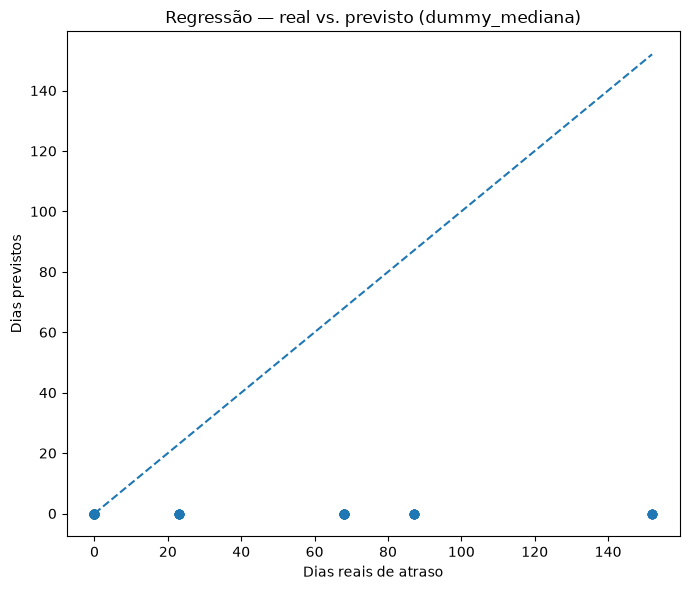

In [12]:
plt.figure(figsize=(7, 6))
plt.scatter(
    reg_test_eval["target_dias_atraso"],
    reg_test_eval["pred_dias_atraso"],
    alpha=0.55,
)
mx = max(
    reg_test_eval["target_dias_atraso"].max(),
    reg_test_eval["pred_dias_atraso"].max(),
)
plt.plot([0, mx], [0, mx], linestyle="--")
plt.xlabel("Dias reais de atraso")
plt.ylabel("Dias previstos")
plt.title(f"Regressão — real vs. previsto ({best_reg_name})")
plt.tight_layout()
plt.show()


# Parte B — Classificação

In [13]:
clf_train, Xc_train, _, yc_train, wc_train = split_xy(clf_data, "train")
clf_val, Xc_val, _, yc_val, wc_val = split_xy(clf_data, "validation")
clf_test, Xc_test, _, yc_test, wc_test = split_xy(clf_data, "test")

classification_models = {
    "dummy_prior": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "regressao_logistica": Pipeline([
        ("preprocessing", clone(linear_preprocessing)),
        ("model", LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=RANDOM_STATE,
        )),
    ]),
    "random_forest": Pipeline([
        ("preprocessing", clone(tree_preprocessing)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=8,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}


In [14]:
def classification_metrics(y_true, pred, proba, sample_weight=None):
    row = {
        "accuracy": accuracy_score(
            y_true, pred, sample_weight=sample_weight
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, pred, sample_weight=sample_weight
        ),
        "precision": precision_score(
            y_true, pred, sample_weight=sample_weight, zero_division=0
        ),
        "recall": recall_score(
            y_true, pred, sample_weight=sample_weight, zero_division=0
        ),
        "f1": f1_score(
            y_true, pred, sample_weight=sample_weight, zero_division=0
        ),
        "brier": brier_score_loss(
            y_true, proba, sample_weight=sample_weight
        ),
    }

    if pd.Series(y_true).nunique() == 2:
        row["roc_auc"] = roc_auc_score(
            y_true, proba, sample_weight=sample_weight
        )
        row["pr_auc"] = average_precision_score(
            y_true, proba, sample_weight=sample_weight
        )
    else:
        row["roc_auc"] = np.nan
        row["pr_auc"] = np.nan

    return row

fitted_classification = {}
classification_results_050 = []

for name, model in classification_models.items():
    model.fit(Xc_train, yc_train, model__sample_weight=wc_train)
    fitted_classification[name] = model

    for split_name, X_, y_, w_ in [
        ("validation", Xc_val, yc_val, wc_val),
        ("test", Xc_test, yc_test, wc_test),
    ]:
        proba = model.predict_proba(X_)[:, 1]
        pred = (proba >= 0.50).astype(int)

        row = {
            "modelo": name,
            "split": split_name,
            "threshold": 0.50,
        }
        row.update(classification_metrics(y_, pred, proba, w_))
        classification_results_050.append(row)

classification_metrics_050_df = pd.DataFrame(
    classification_results_050
)

display(
    classification_metrics_050_df
    .sort_values(["split", "roc_auc"], ascending=[True, False])
    .reset_index(drop=True)
)


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,dummy_prior,test,0.5000,0.6447,0.5000,0.0000,0.0000,0.0000,0.2315,0.5000,0.3553
1,random_forest,test,0.5000,0.5256,0.5150,0.3702,0.4784,0.4174,0.2900,0.4738,0.5127
2,regressao_logistica,test,0.5000,0.6035,0.5308,0.4141,0.2794,0.3337,0.3265,0.3460,0.4083
3,regressao_logistica,validation,0.5000,0.5814,0.4000,0.0000,0.0000,0.0000,0.3203,0.5307,0.2785
4,dummy_prior,validation,0.5000,0.7267,0.5000,0.0000,0.0000,0.0000,0.2159,0.5000,0.2733
5,random_forest,validation,0.5000,0.4845,0.4440,0.2222,0.3546,0.2732,0.3018,0.4303,0.2333


## 5. Escolha do classificador e threshold usando apenas validation

In [15]:
validation_ranking = (
    classification_metrics_050_df[
        classification_metrics_050_df["split"].eq("validation")
    ]
    .sort_values(["roc_auc", "pr_auc"], ascending=False)
)

display(validation_ranking)

best_clf_name = validation_ranking.iloc[0]["modelo"]
best_clf = fitted_classification[best_clf_name]

print("Melhor classificador na validação:", best_clf_name)


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
2,regressao_logistica,validation,0.5000,0.5814,0.4000,0.0000,0.0000,0.0000,0.3203,0.5307,0.2785
0,dummy_prior,validation,0.5000,0.7267,0.5000,0.0000,0.0000,0.0000,0.2159,0.5000,0.2733
4,random_forest,validation,0.5000,0.4845,0.4440,0.2222,0.3546,0.2732,0.3018,0.4303,0.2333


Melhor classificador na validação: regressao_logistica


In [16]:
val_proba = best_clf.predict_proba(Xc_val)[:, 1]

threshold_grid = np.arange(0.10, 0.91, 0.02)
threshold_rows = []

for threshold in threshold_grid:
    pred = (val_proba >= threshold).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "balanced_accuracy": balanced_accuracy_score(
            yc_val, pred, sample_weight=wc_val
        ),
        "precision": precision_score(
            yc_val, pred, sample_weight=wc_val, zero_division=0
        ),
        "recall": recall_score(
            yc_val, pred, sample_weight=wc_val, zero_division=0
        ),
        "f1": f1_score(
            yc_val, pred, sample_weight=wc_val, zero_division=0
        ),
    })

threshold_table = pd.DataFrame(threshold_rows)

best_threshold = float(
    threshold_table
    .sort_values(
        ["balanced_accuracy", "f1"],
        ascending=False,
    )
    .iloc[0]["threshold"]
)

print(f"Threshold escolhido: {best_threshold:.2f}")
display(
    threshold_table
    .sort_values(
        ["balanced_accuracy", "f1"],
        ascending=False,
    )
    .head(10)
)


Threshold escolhido: 0.24


,threshold,balanced_accuracy,precision,recall,f1
7,0.2400,0.5697,0.3478,0.4728,0.4008
10,0.3000,0.5569,0.3415,0.4137,0.3741
11,0.3200,0.5569,0.3415,0.4137,0.3741
12,0.3400,0.5569,0.3415,0.4137,0.3741
13,0.3600,0.5569,0.3415,0.4137,0.3741
8,0.2600,0.5402,0.3182,0.4137,0.3597
9,0.2800,0.5402,0.3182,0.4137,0.3597
14,0.3800,0.5273,0.3077,0.3546,0.3295
2,0.1400,0.5245,0.2907,0.5957,0.3907
0,0.1000,0.5204,0.2857,0.6809,0.4025


## 6. Avaliação final no teste

In [17]:
test_proba = best_clf.predict_proba(Xc_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

final_classification_metrics = {
    "modelo": best_clf_name,
    "split": "test",
    "threshold": best_threshold,
    **classification_metrics(
        yc_test,
        test_pred,
        test_proba,
        wc_test,
    ),
}

display(pd.DataFrame([final_classification_metrics]))


,modelo,split,threshold,accuracy,balanced_accuracy,precision,recall,f1,brier,roc_auc,pr_auc
0,regressao_logistica,test,0.2400,0.2241,0.2923,0.2356,0.5276,0.3258,0.3265,0.3460,0.4083


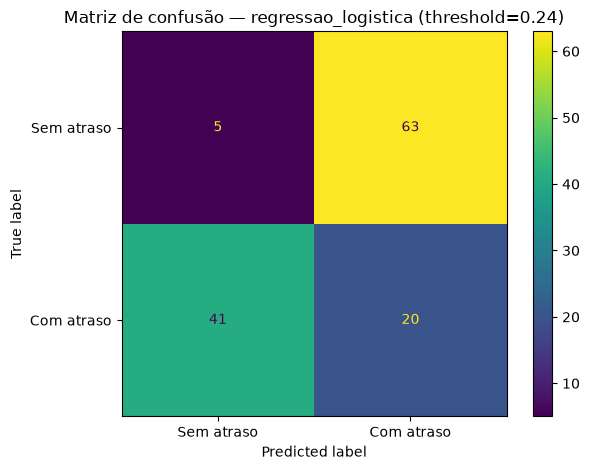

              precision    recall  f1-score   support

  Sem atraso       0.11      0.07      0.09        68
  Com atraso       0.24      0.33      0.28        61

    accuracy                           0.19       129
   macro avg       0.17      0.20      0.18       129
weighted avg       0.17      0.19      0.18       129



In [18]:
ConfusionMatrixDisplay.from_predictions(
    yc_test,
    test_pred,
    display_labels=["Sem atraso", "Com atraso"],
    values_format="d",
)
plt.title(
    f"Matriz de confusão — {best_clf_name} "
    f"(threshold={best_threshold:.2f})"
)
plt.tight_layout()
plt.show()

print(
    classification_report(
        yc_test,
        test_pred,
        target_names=["Sem atraso", "Com atraso"],
        zero_division=0,
    )
)


## 7. Curva de calibração

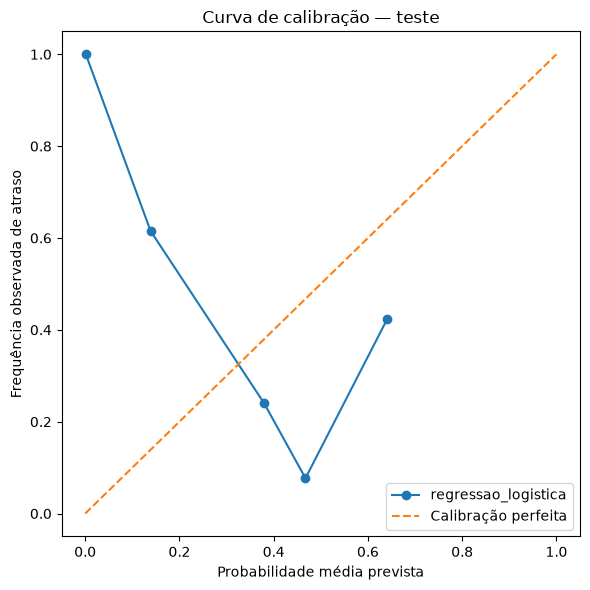

In [19]:
if pd.Series(yc_test).nunique() == 2:
    prob_true, prob_pred = calibration_curve(
        yc_test,
        test_proba,
        n_bins=5,
        strategy="quantile",
    )

    plt.figure(figsize=(6, 6))
    plt.plot(prob_pred, prob_true, marker="o", label=best_clf_name)
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
    plt.xlabel("Probabilidade média prevista")
    plt.ylabel("Frequência observada de atraso")
    plt.title("Curva de calibração — teste")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 8. Avaliação complementar por contrato em horizonte ~90 dias

In [20]:
HORIZONTE_DIAS = 90

fixed_horizon = clf_test.copy()
fixed_horizon["dist_horizonte"] = (
    fixed_horizon["dias_restantes_prazo_vigente"] - HORIZONTE_DIAS
).abs()

fixed_horizon = (
    fixed_horizon
    .sort_values(["id_contrato", "dist_horizonte", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .first()
)

X_fixed = fixed_horizon[features]
fixed_horizon["prob_atraso"] = best_clf.predict_proba(X_fixed)[:, 1]
fixed_horizon["pred_atraso"] = (
    fixed_horizon["prob_atraso"] >= best_threshold
).astype(int)

display(
    fixed_horizon[
        [
            "id_contrato",
            "data_corte",
            "dias_restantes_prazo_vigente",
            "target_atraso",
            "prob_atraso",
            "pred_atraso",
        ]
    ]
)


,id_contrato,data_corte,dias_restantes_prazo_vigente,target_atraso,prob_atraso,pred_atraso
0,217,2025-10-31,100,1.0000,0.0132,0
1,254,2025-05-31,83,0.0000,0.4502,1
2,283,2024-11-30,97,0.0000,0.5033,1
3,287,2025-03-31,84,0.0000,0.4721,1
4,317,2024-11-30,84,1.0000,0.3415,1
5,342,2025-07-18,60,0.0000,0.4175,1
6,375,2026-01-31,104,0.0000,0.4691,1
7,377,2025-04-29,90,1.0000,0.4391,1
8,381,2025-06-30,81,1.0000,0.5025,1


## 9. Importância das features — validação

In [21]:
reg_perm = permutation_importance(
    best_reg,
    Xr_val,
    yr_val,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
)

reg_importance = (
    pd.DataFrame({
        "feature": features,
        "importance_mean": reg_perm.importances_mean,
        "importance_std": reg_perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
)

print("Importância — regressão")
display(reg_importance.head(15))


Importância — regressão


,feature,importance_mean,importance_std
0,valor_total_contrato,0.0000,0.0000
1,prazo_original_dias,0.0000,0.0000
2,dias_desde_os,0.0000,0.0000
3,dias_restantes_prazo_vigente,0.0000,0.0000
4,pct_prazo_consumido,0.0000,0.0000
5,qtd_aditivos_prazo,0.0000,0.0000
6,dias_aditados_acumulados,0.0000,0.0000
7,qtd_aditivos_valor,0.0000,0.0000
8,pct_parcelas_concluidas_vs_previstas,0.0000,0.0000
9,atraso_medio_parcelas_dias,0.0000,0.0000


In [22]:
if yc_val.nunique() == 2:
    clf_perm = permutation_importance(
        best_clf,
        Xc_val,
        yc_val,
        scoring="roc_auc",
        n_repeats=10,
        random_state=RANDOM_STATE,
    )

    clf_importance = (
        pd.DataFrame({
            "feature": features,
            "importance_mean": clf_perm.importances_mean,
            "importance_std": clf_perm.importances_std,
        })
        .sort_values("importance_mean", ascending=False)
    )

    print("Importância — classificação")
    display(clf_importance.head(15))


Importância — classificação


,feature,importance_mean,importance_std
9,atraso_medio_parcelas_dias,0.2654,0.0663
16,atraso_medio_liberacao_dias,0.0768,0.0135
5,qtd_aditivos_prazo,0.0714,0.0144
12,atraso_medio_parcelas_90d,0.0579,0.0286
0,valor_total_contrato,0.0566,0.0247
3,dias_restantes_prazo_vigente,0.0364,0.0202
10,atraso_maximo_parcelas_dias,0.0323,0.0160
7,qtd_aditivos_valor,0.0196,0.0225
2,dias_desde_os,0.0171,0.0236
18,classificacao_contrato,0.0106,0.0225


## 10. Sanity checks e salvamento

In [23]:
contract_split_counts = (
    model_data.groupby("id_contrato")["split_modelagem"].nunique()
)
assert contract_split_counts.max() == 1

forbidden = {
    "id_contrato",
    "numero_contrato",
    "status_final_controle",
    "data_conclusao_definitiva",
    "data_conclusao_controle",
    "data_conclusao_sistema_controle",
    "data_termino_vigente_final_controle",
    "target_dias_atraso",
    "target_atraso",
    "flag_apto_treino",
    "sample_weight_contrato",
    "sample_weight_contrato_raw",
    "split_modelagem",
    "split_contrato_temporal",
}
assert not (set(features) & forbidden)
assert clf_data["dias_restantes_prazo_vigente"].ge(0).all()

# Nenhum snapshot supervisionado pode ocorrer na/apos a conclusão definitiva.
assert (
    model_data["data_corte"]
    < model_data["data_conclusao_definitiva"]
).all()

# Target binário deve ser consistente com o target em dias.
target_bin_recalc = (model_data["target_dias_atraso"] > 0).astype(int)
assert (
    target_bin_recalc.values
    == model_data["target_atraso"].astype(int).values
).all()

regression_metrics_df.to_csv(
    METRICS_DIR / "etapa2_regressao_comparacao.csv",
    index=False,
    encoding="utf-8-sig",
)

classification_metrics_050_df.to_csv(
    METRICS_DIR / "etapa2_classificacao_comparacao_threshold_050.csv",
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame([final_classification_metrics]).to_csv(
    METRICS_DIR / "etapa2_classificacao_teste_final.csv",
    index=False,
    encoding="utf-8-sig",
)

threshold_table.to_csv(
    METRICS_DIR / "etapa2_thresholds_validacao.csv",
    index=False,
    encoding="utf-8-sig",
)

horizon_reg.to_csv(
    METRICS_DIR / "etapa2_regressao_por_antecedencia.csv",
    index=False,
    encoding="utf-8-sig",
)

fixed_horizon[
    [
        "id_contrato", "data_corte",
        "dias_restantes_prazo_vigente",
        "target_atraso", "prob_atraso", "pred_atraso",
    ]
].to_csv(
    PREDICTIONS_DIR / "etapa2_classificacao_horizonte_90d.csv",
    index=False,
    encoding="utf-8-sig",
)

reg_importance.to_csv(
    METRICS_DIR / "etapa2_regressao_importancia_permutacao.csv",
    index=False,
    encoding="utf-8-sig",
)

if "clf_importance" in globals():
    clf_importance.to_csv(
        METRICS_DIR / "etapa2_classificacao_importancia_permutacao.csv",
        index=False,
        encoding="utf-8-sig",
    )

print("Sanity checks concluídos.")
print("Resultados salvos em:", ARTIFACTS_DIR)


Sanity checks concluídos.
Resultados salvos em: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\artifacts


# Critério para avançar para a próxima etapa

## Regressão
Procure:
- menor MAE;
- menor RMSE;
- maior R²;
- menor viés médio;
- melhora por faixa de antecedência.

